In [68]:

import numpy as np
import pandas as pd

rng = np.random.default_rng(55)

n = 1200

students = pd.DataFrame({
    "student_id": range(1, n + 1),
    "county": rng.choice(
        ["Nairobi", "Kisumu", "Nakuru", "Mombasa", "Nyeri", "Turkana"], n
    ),
    "school_type": rng.choice(
        ["Public", "Private"], n, p=[0.75, 0.25]
    ),
    "gender": rng.choice(["F", "M"], n),
    "attendance_rate": rng.beta(8, 2, n).round(2),
    "study_hours": rng.gamma(2.5, 2.0, n).round(1),
})

base = (
    35
    + 30 * students["attendance_rate"]
    + 2.2 * students["study_hours"]
    + np.where(students["school_type"] == "Private", 6, 0)
)

students["math"] = (
    base + rng.normal(0, 8, n)
).clip(0, 100).round(0)

students["english"] = (
    base + rng.normal(3, 7, n)
).clip(0, 100).round(0)

students["science"] = (
    base + rng.normal(-2, 9, n)
).clip(0, 100).round(0)

students.to_csv("student_performance.csv", index=False)

print("Dataset created successfully!")
print("Dataset shape:", students.shape)
display(students.head())


Dataset created successfully!
Dataset shape: (1200, 9)


,student_id,county,school_type,gender,attendance_rate,study_hours,math,english,science
0,1,Turkana,Private,M,0.77,6.5,81.0,71.0,73.0
1,2,Nyeri,Private,M,0.97,8.5,100.0,86.0,90.0
2,3,Nyeri,Private,F,0.98,8.0,82.0,89.0,90.0
3,4,Turkana,Public,M,0.93,6.0,83.0,91.0,72.0
4,5,Kisumu,Private,F,0.67,6.1,76.0,69.0,62.0


In [69]:

import os
import pandas as pd

print("Current folder:", os.getcwd())
print("CSV exists:", os.path.exists("student_performance.csv"))

df = pd.read_csv("student_performance.csv")

print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())
print("Missing values:")
print(df.isnull().sum())

display(df.head())


Current folder: /content
CSV exists: True
Dataset shape: (1200, 9)
Columns: ['student_id', 'county', 'school_type', 'gender', 'attendance_rate', 'study_hours', 'math', 'english', 'science']
Missing values:
student_id         0
county             0
school_type        0
gender             0
attendance_rate    0
study_hours        0
math               0
english            0
science            0
dtype: int64


,student_id,county,school_type,gender,attendance_rate,study_hours,math,english,science
0,1,Turkana,Private,M,0.77,6.5,81.0,71.0,73.0
1,2,Nyeri,Private,M,0.97,8.5,100.0,86.0,90.0
2,3,Nyeri,Private,F,0.98,8.0,82.0,89.0,90.0
3,4,Turkana,Public,M,0.93,6.0,83.0,91.0,72.0
4,5,Kisumu,Private,F,0.67,6.1,76.0,69.0,62.0


In [70]:

import matplotlib.pyplot as plt
from pathlib import Path

Path("figures").mkdir(exist_ok=True)

# Average of the three subject scores
df["average_score"] = df[["math", "english", "science"]].mean(axis=1)

# Performance categories
df["performance_band"] = pd.cut(
    df["average_score"],
    bins=[-float("inf"), 60, 75, float("inf")],
    labels=["At Risk", "Meeting", "Exceeding"],
    right=False
)

print("Updated dataset shape:", df.shape)
display(df.head())
print("\nPerformance band counts:")
print(df["performance_band"].value_counts())


Updated dataset shape: (1200, 11)


,student_id,county,school_type,gender,attendance_rate,study_hours,math,english,science,average_score,performance_band
0,1,Turkana,Private,M,0.77,6.5,81.0,71.0,73.0,75.0,Exceeding
1,2,Nyeri,Private,M,0.97,8.5,100.0,86.0,90.0,92.0,Exceeding
2,3,Nyeri,Private,F,0.98,8.0,82.0,89.0,90.0,87.0,Exceeding
3,4,Turkana,Public,M,0.93,6.0,83.0,91.0,72.0,82.0,Exceeding
4,5,Kisumu,Private,F,0.67,6.1,76.0,69.0,62.0,69.0,Meeting



Performance band counts:
performance_band
Meeting      672
Exceeding    429
At Risk       99
Name: count, dtype: int64


In [71]:

# 1. STRUCTURE

print("Number of students:", len(df))
print("Number of variables:", df.shape[1])

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nNumerical summary:")
display(df.describe().T)


Number of students: 1200
Number of variables: 11

Data types:
student_id             int64
county                object
school_type           object
gender                object
attendance_rate      float64
study_hours          float64
math                 float64
english              float64
science              float64
average_score        float64
performance_band    category
dtype: object

Missing values:
student_id          0
county              0
school_type         0
gender              0
attendance_rate     0
study_hours         0
math                0
english             0
science             0
average_score       0
performance_band    0
dtype: int64

Duplicate rows: 0

Numerical summary:


,count,mean,std,min,25%,50%,75%,max
student_id,1200.0,600.500000,346.554469,1.000000,300.750000,600.500000,900.250000,1200.0
attendance_rate,1200.0,0.803650,0.119153,0.330000,0.730000,0.820000,0.900000,1.0
study_hours,1200.0,5.077917,3.028098,0.200000,2.900000,4.500000,6.700000,23.3
math,1200.0,71.889167,10.858490,37.000000,65.000000,72.000000,79.000000,100.0
english,1200.0,74.520833,10.486557,47.000000,67.000000,74.000000,81.000000,100.0
science,1200.0,69.612500,12.022456,35.000000,61.000000,69.000000,78.000000,100.0
average_score,1200.0,72.007500,9.105740,48.333333,65.666667,71.666667,77.666667,100.0


### Structure — Interpretation

The dataset contains 1,200 student records, with each row representing one student. It includes student identification, county, school type, gender, attendance rate, study hours and three subject scores. Two additional variables, average_score and performance_band, are created during analysis. Numerical variables describe measurements and scores, while categorical variables describe student groups. Missing values and duplicate records were checked to assess data quality.

In [72]:

# 2. UNIVARIATE

# Numerical variables: centre, spread and shape
numeric_cols = df.select_dtypes(include="number").columns

print("Numerical summary:")
display(df[numeric_cols].describe().T)

print("\nSkewness:")
display(df[numeric_cols].skew().to_frame("Skewness"))

# Categorical variables: counts and percentages
categorical_cols = [
    "county", "school_type", "gender", "performance_band"
]

for col in categorical_cols:
    print(f"\n{col}")
    summary = pd.DataFrame({
        "Count": df[col].value_counts(),
        "Share (%)": df[col].value_counts(normalize=True) * 100
    })
    display(summary.round(2))

# Study-hour outliers using IQR
q1 = df["study_hours"].quantile(0.25)
q3 = df["study_hours"].quantile(0.75)
iqr = q3 - q1

lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr

outliers = df[
    (df["study_hours"] < lower) |
    (df["study_hours"] > upper)
]

print("Study-hours lower bound:", lower)
print("Study-hours upper bound:", upper)
print("Number of flagged outliers:", len(outliers))

display(outliers[["student_id", "study_hours"]].head(10))


Numerical summary:


,count,mean,std,min,25%,50%,75%,max
student_id,1200.0,600.500000,346.554469,1.000000,300.750000,600.500000,900.250000,1200.0
attendance_rate,1200.0,0.803650,0.119153,0.330000,0.730000,0.820000,0.900000,1.0
study_hours,1200.0,5.077917,3.028098,0.200000,2.900000,4.500000,6.700000,23.3
math,1200.0,71.889167,10.858490,37.000000,65.000000,72.000000,79.000000,100.0
english,1200.0,74.520833,10.486557,47.000000,67.000000,74.000000,81.000000,100.0
science,1200.0,69.612500,12.022456,35.000000,61.000000,69.000000,78.000000,100.0
average_score,1200.0,72.007500,9.105740,48.333333,65.666667,71.666667,77.666667,100.0



Skewness:


,Skewness
student_id,0.000000
attendance_rate,-0.857542
study_hours,1.173774
math,0.101623
english,0.159639
science,0.106528
average_score,0.261912



county


...

,Count,Share (%)
gender,,
F,612,51.0
M,588,49.0



performance_band


,Count,Share (%)
performance_band,,
Meeting,672,56.00
Exceeding,429,35.75
At Risk,99,8.25


Study-hours lower bound: -2.8000000000000003
Study-hours upper bound: 12.4
Number of flagged outliers: 29


,student_id,study_hours
94,95,15.2
114,115,12.5
119,120,15.0
213,214,13.5
271,272,17.1
310,311,15.5
364,365,15.3
434,435,16.2
502,503,14.6
566,567,13.5


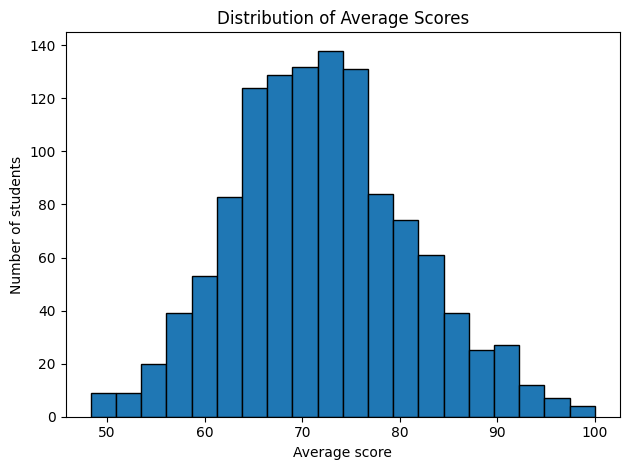

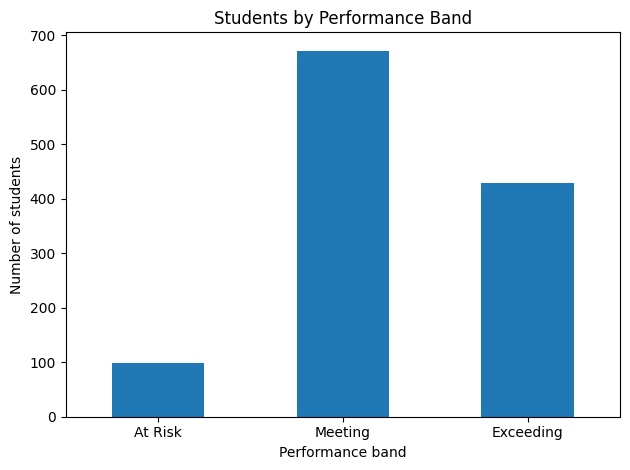

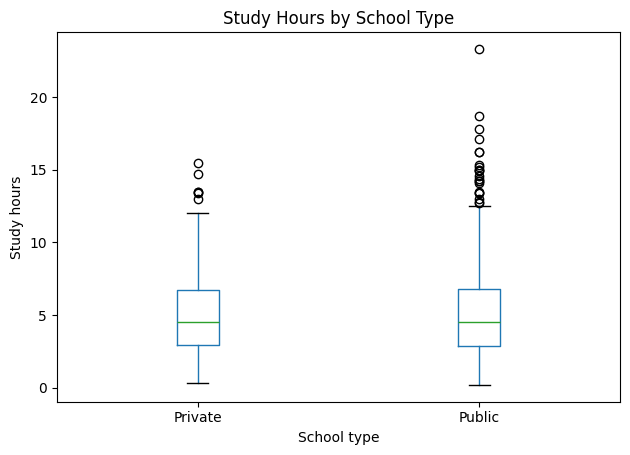

Charts saved successfully.


In [73]:

# Chart 1: Histogram
ax = df["average_score"].plot(
    kind="hist", bins=20,
    title="Distribution of Average Scores",
    edgecolor="black"
)
ax.set_xlabel("Average score")
ax.set_ylabel("Number of students")
plt.tight_layout()
plt.savefig("figures/average_score_histogram.png", dpi=150)
plt.show()

# Chart 2: Bar chart
ax = df["performance_band"].value_counts().reindex(
    ["At Risk", "Meeting", "Exceeding"]
).plot(
    kind="bar",
    title="Students by Performance Band"
)
ax.set_xlabel("Performance band")
ax.set_ylabel("Number of students")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("figures/performance_band_bar.png", dpi=150)
plt.show()

# Chart 3: Box plot
ax = df.boxplot(column="study_hours", by="school_type", grid=False)
ax.set_title("Study Hours by School Type")
ax.set_xlabel("School type")
ax.set_ylabel("Study hours")
plt.suptitle("")
plt.tight_layout()
plt.savefig("figures/study_hours_boxplot.png", dpi=150)
plt.show()

print("Charts saved successfully.")


In [74]:

# 3. BIVARIATE

numeric_df = df.select_dtypes(include="number")
correlation_matrix = numeric_df.corr()

print("Correlation matrix:")
display(correlation_matrix.round(3))

print("\nThree strongest correlations with average_score:")
corr = correlation_matrix["average_score"].drop("average_score")
display(
    corr.loc[corr.abs().sort_values(ascending=False).head(3).index]
    .to_frame("Correlation")
    .round(3)
)

# Average scores by gender, school type and county
for col in ["gender", "school_type", "county"]:
    print(f"\nAverage score by {col}:")
    display(
        df.groupby(col, observed=True)["average_score"]
        .agg(["count", "mean", "median"])
        .round(2)
        .sort_values("mean", ascending=False)
    )

# County with the highest At Risk share
county_risk = (
    df.assign(at_risk=df["performance_band"].eq("At Risk"))
    .groupby("county", observed=True)["at_risk"]
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

print("\nAt Risk percentage by county:")
display(county_risk.round(2))
print("County with highest At Risk share:", county_risk.index[0])


Correlation matrix:


,student_id,attendance_rate,study_hours,math,english,science,average_score
student_id,1.000,-0.016,-0.016,0.027,0.002,-0.019,0.003
attendance_rate,-0.016,1.000,-0.029,0.300,0.327,0.260,0.359
study_hours,-0.016,-0.029,1.000,0.560,0.624,0.550,0.704
math,0.027,0.300,0.560,1.000,0.559,0.459,0.814
english,0.002,0.327,0.624,0.559,1.000,0.502,0.827
science,-0.019,0.260,0.550,0.459,0.502,1.000,0.815
average_score,0.003,0.359,0.704,0.814,0.827,0.815,1.000



Three strongest correlations with average_score:


,Correlation
english,0.827
science,0.815
math,0.814



Average score by gender:


...


Average score by county:


,count,mean,median
county,,,
Kisumu,208,73.07,72.50
Mombasa,212,72.17,72.17
Nairobi,184,71.96,72.17
Nyeri,203,71.94,71.33
Nakuru,202,71.84,70.83
Turkana,191,70.97,70.00



At Risk percentage by county:


,at_risk
county,
Nairobi,9.24
Mombasa,8.96
Nyeri,8.87
Kisumu,8.17
Turkana,7.85
Nakuru,6.44


County with highest At Risk share: Nairobi


In [75]:

# 4. MULTIVARIATE

df["attendance_band"] = pd.cut(
    df["attendance_rate"] * 100,
    bins=[-1, 60, 75, 90, 100],
    labels=["Below 60%", "60–74%", "75–89%", "90–100%"]
)

df["study_hour_quartile"] = pd.qcut(
    df["study_hours"],
    q=4,
    labels=["Q1 Lowest", "Q2", "Q3", "Q4 Highest"],
    duplicates="drop"
)

attendance_pivot = pd.pivot_table(
    df,
    index="attendance_band",
    columns="school_type",
    values="average_score",
    aggfunc="mean",
    observed=True
)

print("Average score by attendance band and school type:")
display(attendance_pivot.round(2))

print("\nSchool-type gap within attendance bands:")
display((attendance_pivot["Private"] - attendance_pivot["Public"])
        .to_frame("Private minus Public").round(2))

study_pivot = pd.pivot_table(
    df,
    index="study_hour_quartile",
    columns="school_type",
    values="average_score",
    aggfunc="mean",
    observed=True
)

print("Average score by study-hour quartile and school type:")
display(study_pivot.round(2))

print("\nSchool-type gap within study-hour quartiles:")
display((study_pivot["Private"] - study_pivot["Public"])
        .to_frame("Private minus Public").round(2))


Average score by attendance band and school type:


school_type,Private,Public
attendance_band,,
Below 60%,67.38,61.26
60–74%,73.59,67.81
75–89%,76.82,71.17
90–100%,79.39,74.19



School-type gap within attendance bands:


,Private minus Public
attendance_band,
Below 60%,6.11
60–74%,5.78
75–89%,5.66
90–100%,5.21


Average score by study-hour quartile and school type:


school_type,Private,Public
study_hour_quartile,,
Q1 Lowest,69.51,63.82
Q2,74.92,67.12
Q3,76.18,71.18
Q4 Highest,83.65,80.06



School-type gap within study-hour quartiles:


,Private minus Public
study_hour_quartile,
Q1 Lowest,5.69
Q2,7.80
Q3,5.00
Q4 Highest,3.59


Slope: 2.117
R-squared: 0.495


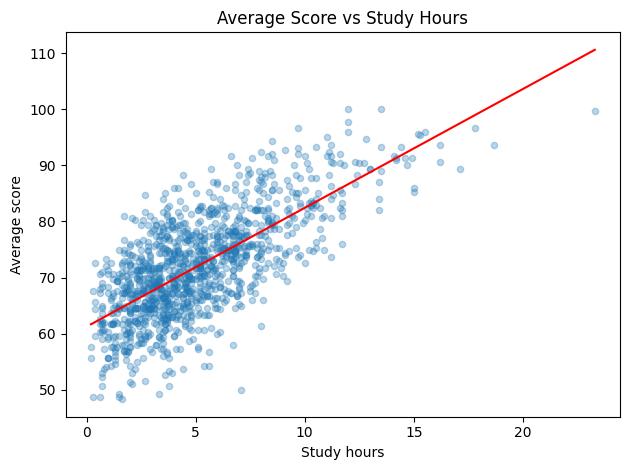

In [76]:

# 5. HYPOTHESES

trend_data = df[["study_hours", "average_score"]].dropna()

slope, intercept = np.polyfit(
    trend_data["study_hours"],
    trend_data["average_score"],
    1
)

predicted = slope * trend_data["study_hours"] + intercept

ss_res = ((trend_data["average_score"] - predicted) ** 2).sum()
ss_tot = (
    (trend_data["average_score"] - trend_data["average_score"].mean()) ** 2
).sum()

r_squared = 1 - ss_res / ss_tot

print(f"Slope: {slope:.3f}")
print(f"R-squared: {r_squared:.3f}")

ax = trend_data.plot(
    kind="scatter",
    x="study_hours",
    y="average_score",
    alpha=0.3,
    title="Average Score vs Study Hours"
)

x_line = np.linspace(
    trend_data["study_hours"].min(),
    trend_data["study_hours"].max(),
    100
)
ax.plot(x_line, slope * x_line + intercept, color="red")
ax.set_xlabel("Study hours")
ax.set_ylabel("Average score")
plt.tight_layout()
plt.savefig("figures/study_hours_trend.png", dpi=150)
plt.show()


## Findings

1. **Performance distribution:** Report the mean average score and the percentage of students in each performance band.
2. **Learners at risk:** Identify the county with the highest percentage of At Risk learners.
3. **Study hours:** Report the correlation with average score, trend-line slope and R².
4. **School-type gap:** Compare public and private school mean scores and report the difference.
5. **Attendance and study hours:** Use the pivot tables to describe whether the school-type gap persists within attendance bands and study-hour quartiles.

## Recommendations

1. Prioritise learner-support resources for schools and counties with high shares of At Risk students, using verified school-level results to direct tutoring and remedial support.
2. Support attendance monitoring and structured study programmes, then evaluate progress using subsequent assessment results.

## Limitations

This analysis uses observational data from 1,200 students. Correlation and group differences do not prove causation. Other factors, including prior achievement, teaching quality and household resources, may influence results. Study-hour outliers may be genuine observations rather than errors. The linear trend is not a validated prediction model, and the dataset contains no dates for time-series analysis.